# PS- 1C: FNN for CIFAR10 Classification
Open this notebook with `PS- 1C` as the working folder and run the cells from top to bottom using a Python 3 kernel with TensorFlow, pandas, matplotlib, and scikit-learn installed. Both CSV files are loaded from this folder only.

Each image is already flattened into 3072 pixels (32 x 32 x 3). The training CSV has a `label` column, but the supplied test CSV has no labels. We hold out 20% of the labeled training data for evaluation and use the supplied test CSV for predictions.


In [13]:
# a. Import all necessary packages
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam


In [14]:
# b. Load updated CIFAR10 CSV and split it into training and testing data.
data = pd.read_csv("cifar-10.csv", dtype="uint8")
x = data.drop("label", axis=1).values.astype("float32") / 255.0
y = data["label"].values
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)


In [ ]:
# Show 10 training images in a 2 x 5 subplot.
image_labels = y_train[:10]
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(3, 32, 32).transpose(1, 2, 0))
    plt.title(f"Label: {image_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [15]:
# c. Define the FNN: 3072 inputs, 128 hidden neurons, 10 outputs
model = Sequential([
    Input(shape=(3072,)),
    Dense(128, activation="relu"),
    Dense(64,activation="relu"),
    Dense(10, activation="softmax")
])
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 402,250 (1.53 MB)

 Trainable params: 402,250 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# d. Train the model using Adam
# Sparse categorical cross-entropy uses integer class labels directly.
model.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=11, batch_size=32, verbose=2)


Epoch 1/11
1250/1250 - 26s - 21ms/step - accuracy: 0.3127 - loss: 1.8958
Epoch 2/11
1250/1250 - 21s - 17ms/step - accuracy: 0.3756 - loss: 1.7316
Epoch 3/11
1250/1250 - 19s - 15ms/step - accuracy: 0.4034 - loss: 1.6678
Epoch 4/11
1250/1250 - 20s - 16ms/step - accuracy: 0.4194 - loss: 1.6183
Epoch 5/11
1250/1250 - 20s - 16ms/step - accuracy: 0.4317 - loss: 1.5840
Epoch 6/11
1250/1250 - 22s - 18ms/step - accuracy: 0.4444 - loss: 1.5511
Epoch 7/11
1250/1250 - 19s - 15ms/step - accuracy: 0.4523 - loss: 1.5314
Epoch 8/11
1250/1250 - 16s - 13ms/step - accuracy: 0.4548 - loss: 1.5127
Epoch 9/11
1250/1250 - 20s - 16ms/step - accuracy: 0.4643 - loss: 1.4932
Epoch 10/11
1250/1250 - 19s - 15ms/step - accuracy: 0.4679 - loss: 1.4853
Epoch 11/11
1250/1250 - 19s - 15ms/step - accuracy: 0.4736 - loss: 1.4664


In [17]:
# e. Evaluate on the held-out labeled data
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Held-out test loss: {loss:.4f}")
print(f"Held-out test accuracy: {accuracy * 100:.2f}%")

# Predict classes for the supplied unlabeled test CSV.
predictions = model.predict(x_predict, verbose=0).argmax(axis=1)
print("First 10 predictions (class IDs):", predictions[:10])


Held-out test loss: 1.5222
Held-out test accuracy: 45.93%
First 10 predictions (class IDs): [4 9 9 8 4 6 3 6 2 1]


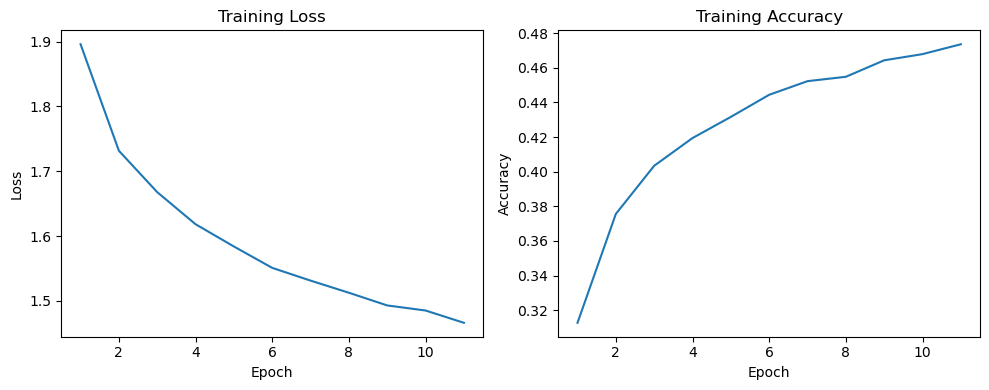

In [18]:
# f. Plot the training loss and accuracy
epochs = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()
